# Tutorial 3g: Model Glass and Continuous Nd/Vd Optimization

Tutorial 3e optimized the glasses with `GlassExpert`, which is a *categorical* search over a fixed list of catalogue glasses. This tutorial takes the complementary route:

1. **Model glass.** Every lens is converted to an `optiland.materials.ModelMaterial`: a Buchdahl polynomial fitted to the glass descriptors `Nd` (index at the d-line) and `Vd` (Abbe number). Both descriptors become ordinary continuous variables, so the optimizer is free to invent glasses that no catalogue contains.
2. **Snap to reality.** Each fictitious glass is projected back onto a real catalogue glass with `optiland.materials.find_closest_glass`, and the geometry is re-optimized.

The starting system is the same deliberately poor six-lens design used in Tutorial 3e.

## Dispersion routes: visible vs infrared

`ModelMaterial` is a 6th-order Buchdahl polynomial built from three glass descriptors: `nd` (index at the d-line), `Vd` (Abbe number) and `dPgF` (deviation of the relative partial dispersion). The model has two variants, called *routes*, and the tutorial below uses the visible one.

**Visible route (default).** For systems that work at visible wavelengths. The three descriptors are enough to build the polynomial, so no extra input is required.

**Infrared route.** For systems that work beyond the visible band, where `(nd, Vd, dPgF)` no longer constrain the near-IR curve shape well. It adds one descriptor, `P_ref`, the relative partial dispersion evaluated at the reference wavelength `lambda_ref`:

$$
P_\mathrm{ref} = \frac{n(\lambda_\mathrm{ref}) - n_d}{(n_d - 1)/V_d}.
$$

**Why `lambda_ref` defaults to 1.55 um.** The IR regression matrix shipped with Optiland was built from commercial glasses with `P_ref` evaluated at 1.55 um, the reference wavelength used for free-space-optics work in this model. The matrix therefore expects the descriptor at that wavelength, not at the design wavelength: a `P_ref` measured elsewhere describes a different quantity than the one the matrix was calibrated on. The updater consequently uses `ModelMaterial.IR_REF_WTH = 1.55 um` whenever the IR route is selected, and evaluates `P_ref` from the current glass at the same wavelength. The anchor at 1.55 um is then reproduced exactly, independently of the system's primary wavelength.

**How the route is chosen.** `OpticUpdater` (used by `set_index`, `set_abbe` and `GlassExpert`) inspects the optic's primary wavelength:

- primary <= 0.78 um (`ModelMaterial.MAX_VISIBLE_WTH`): visible route, `P_ref` and `lambda_ref` stay unset;
- primary > 0.78 um: IR route, `lambda_ref = 1.55 um` (`IR_REF_WTH`) and `P_ref` is computed from the current glass at 1.55 um.

A `ModelMaterial` that already stores a `P_ref`/`lambda_ref` pair keeps them unchanged. When building a model glass from scratch, pass both to select the IR route (`ModelMaterial(nd, vd, dPgF, P_ref=..., lambda_ref=1.55)`); pass neither to keep the visible route. Supplying only one raises a `ValueError`.

This tutorial traces the F, d and C lines (0.4861, 0.5876 and 0.6563 um), so the primary wavelength is 0.5876 um and the visible route is used throughout; the IR descriptors are not needed here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import optiland.backend as be
from optiland import optic, optimization
from optiland.materials import (
    Material,
    MaterialCatalog,
    find_closest_glass,
    get_nd_vd,
    glasses_selection,
)
from optiland.optimization import HistoryObserver, minimize

## The starting point

The design is intentionally mediocre: six identical collimating lenses made of N-BK7, with radii of 1000 mm and no attempt at colour correction.

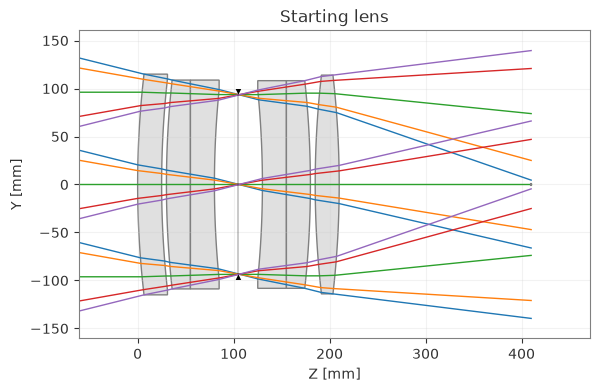

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Starting lens'}, xlabel='Z [mm]', ylabel='Y [mm]'>)

In [2]:
D_LINE = 0.5875618  # [um]
GLASS_SURFACES = (1, 3, 4, 7, 8, 10)
TARGET_FOCAL_LENGTH = 100  # [mm]


class SixLensesStartPoint(optic.Optic):
    """A 6 lens design with very poor quality meant to be optimized."""

    def __init__(self):
        super().__init__()

        self.surfaces.add(index=0, radius=be.inf, thickness=be.inf)
        self.surfaces.add(index=1, radius=1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=2, radius=1000, thickness=5.0)
        self.surfaces.add(index=3, radius=1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=4, radius=be.inf, thickness=25, material="N-BK7")
        self.surfaces.add(index=5, radius=1000, thickness=25)
        self.surfaces.add(index=6, radius=be.inf, thickness=25.0, is_stop=True)
        self.surfaces.add(index=7, radius=-1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=8, radius=be.inf, thickness=25, material="N-BK7")
        self.surfaces.add(index=9, radius=-1000, thickness=5.0)
        self.surfaces.add(index=10, radius=1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=11, radius=-1000, thickness=200)
        self.surfaces.add(index=12)

        self.set_aperture(aperture_type="imageFNO", value=5)
        self.fields.set_type(field_type="angle")

        self.fields.add(y=-14)
        self.fields.add(y=-10)
        self.fields.add(y=0)
        self.fields.add(y=10)
        self.fields.add(y=14)

        self.wavelengths.add(value=0.4861)
        self.wavelengths.add(value=0.5876, is_primary=True)
        self.wavelengths.add(value=0.6563)


lens = SixLensesStartPoint()
lens.draw(title="Starting lens")

In [3]:
lens.info()

╒════╤═══════════════╤═══════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment   │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪═══════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │           │      inf │         inf │ Air        │       0 │        116.634  │
│  1 │ Standard      │           │     1000 │          25 │ N-BK7      │       0 │        116.634  │
│  2 │ Standard      │           │     1000 │           5 │ Air        │       0 │        111.531  │
│  3 │ Standard      │           │     1000 │          25 │ N-BK7      │       0 │        110.271  │
│  4 │ Planar        │           │      inf │          25 │ N-BK7      │       0 │        105.179  │
│  5 │ Standard      │           │     1000 │          25 │ Air        │       0 │        100.087  │
│  6 │ Stop - Planar │           │      inf │          25 │ Air        │       0 │         

## Step 1 - from catalogue glass to model glass

A `ModelMaterial` is defined by four descriptors: `Nd`, `Vd`, `dPgF` (the partial-dispersion deviation from the normal line) and, for infrared work, a reference partial dispersion `P_ref` at `lambda_ref`. Optiland can build one from any existing material:

```python
lens.updater.set_index(value, surface_number)   # wavelength=None
```

With `wavelength=None`, `set_index` reads the `Nd`, `Vd` and `dPgF` of the current glass and rebuilds the surface material as a `ModelMaterial`. The Buchdahl fit is anchored on the d, F, C and g lines, so the model glass reproduces the original catalogue glass very closely.

The model is only valid for `1.0 < Nd < 3.0` and `10 < Vd < 100`, which we will respect when setting the variable bounds.

In [4]:
def nd_vd(material):
    """Return Nd and Vd of a catalogue or model glass as plain floats."""
    nd = float(np.ravel(be.to_numpy(material.n(D_LINE)))[0])
    vd = float(np.ravel(be.to_numpy(material.abbe()))[0])
    return nd, vd


before = {k: nd_vd(lens.surfaces[k].material_post) for k in GLASS_SURFACES}

for surface_number in GLASS_SURFACES:
    lens.updater.set_index(before[surface_number][0], surface_number)

print(f"{'surface':>8}{'material':>15}{'Nd':>10}{'Vd':>9}")
for k in GLASS_SURFACES:
    material = lens.surfaces[k].material_post
    nd, vd = nd_vd(material)
    print(f"{k:>8}{type(material).__name__:>15}{nd:>10.5f}{vd:>9.3f}")

 surface       material        Nd       Vd
       1  ModelMaterial   1.51680   64.167
       3  ModelMaterial   1.51680   64.167
       4  ModelMaterial   1.51680   64.167
       7  ModelMaterial   1.51680   64.167
       8  ModelMaterial   1.51680   64.167
      10  ModelMaterial   1.51680   64.167


## Merit function

Tutorial 3e evaluated the spot size only at the primary wavelength, so the merit function had no information about colour. Here the focal length and the RMS spot size are evaluated at **all three wavelengths**: an optimizer can only move `Vd` if the merit function sees chromatic aberration.

- `real_y_intercept_lcs` on the image plane keeps the focal length at 100 mm for five field points, at every wavelength (this is the axial colour constraint).
- `rms_spot_size` with 16 uniform rays per field minimises the spot at every field and wavelength.

Both sets of operands are wrapped in a `make_problem` helper so that the same merit can be rebuilt after the glasses are replaced.

In [5]:
def make_problem(lens, optimize_glass=True):
    """Build the merit function, the geometric variables and (optionally) glass variables."""
    problem = optimization.OptimizationProblem()

    # Focal length at every field and every wavelength.
    for wavelength in lens.wavelengths:
        for k, hy in enumerate([-1, -0.714, 0, 0.714, 1]):
            input_data = {
                "optic": lens,
                "surface_number": 12,
                "Hx": 0,
                "Hy": hy,
                "Px": 0,
                "Py": 0,
                "wavelength": wavelength.value,
            }
            problem.add_operand(
                operand_type="real_y_intercept_lcs",
                target=TARGET_FOCAL_LENGTH
                * be.tan(be.deg2rad(lens.fields.y_fields[k])),
                weight=1,
                input_data=input_data,
            )

    # RMS spot size at every field and every wavelength.
    for field in lens.fields.get_field_coords():
        for wavelength in lens.wavelengths:
            input_data = {
                "optic": lens,
                "surface_number": 12,
                "Hx": field[0],
                "Hy": field[1],
                "num_rays": 16,
                "wavelength": wavelength.value,
                "distribution": "uniform",
            }
            problem.add_operand(
                operand_type="rms_spot_size",
                target=0.0,
                weight=10,
                input_data=input_data,
            )

    # Curvatures.
    for surface_number in (1, 2, 3, 5, 7, 9, 10, 11):
        problem.add_variable(
            lens, "radius", surface_number=surface_number, min_val=-500, max_val=500
        )

    # Thicknesses.
    thickness_bounds = {
        1: (8, 20),
        2: (0.4, 5),
        3: (8, 20),
        4: (3, 10),
        5: (10, 20),
        6: (10, 20),
        7: (3, 20),
        8: (8, 20),
        9: (0.4, 5),
        10: (6, 20),
        11: (20, 45),
    }
    for surface_number, (lo, hi) in thickness_bounds.items():
        problem.add_variable(
            lens, "thickness", surface_number=surface_number, min_val=lo, max_val=hi
        )

    # Glass: index at the d-line and Abbe number, both continuous.
    if optimize_glass:
        for surface_number in GLASS_SURFACES:
            problem.add_variable(
                lens,
                "index",
                surface_number=surface_number,
                wavelength=None,
                min_val=1.40,
                max_val=2.00,
            )
            problem.add_variable(
                lens,
                "abbe",
                surface_number=surface_number,
                min_val=20,
                max_val=90,
            )

    return problem


problem = make_problem(lens, optimize_glass=True)
merit_start = problem.sum_squared()
print(f"variables: {len(problem.variables)}   starting merit: {merit_start:.3e}")
problem.info()

variables: 31   starting merit: 3.925e+06
╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │            3.92499e+06 │                 0 │
╘════╧════════════════════════╧═══════════════════╛


╒════╤══════════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type         │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ real y intercept lcs │  -24.933 │              │              │        1 │             1 │ -66.044 │ -41.111 │           0.04 │
│  1 │ real y intercept lcs │  -17.633 │              │              │        1 │             1 │ -46.902 │ -29.269 │           0.02 │
│  2 │ real y intercept lcs │    0     │              │              │        1 │             1 │   0     │   0     │           0    │
│  3 │ real y intercept lcs │   17.633 │              │              │        1 │             1 │  46.902 │  29.269 │           0.02 │
│  4 │ real y intercept lcs │   24.933 │              │

## Optimizing Nd and Vd continuously

The `index` variable moves `Nd` (it calls `updater.set_index`, which rebuilds the `ModelMaterial` with the new index while keeping `Vd` and `dPgF`). The `abbe` variable moves `Vd` through `updater.set_abbe`, which keeps `Nd` and `dPgF`.

`dPgF` is deliberately left at its starting value: the six model glasses therefore share the dispersion curve shape of N-BK7 and differ only in `Nd` and `Vd`.

The problem is fully continuous, so Optiland's native damped least squares (`"dls"`) can solve it.

In [6]:
import warnings

# Trial designs during optimisation can vignette an entire field; Optiland
# scores them as very poor, but NumPy warns about the empty ray bundle first.
warnings.filterwarnings("ignore", message="Mean of empty slice")

history = HistoryObserver()
result = minimize(problem, "dls", observers=[history])

merit_continuous = problem.sum_squared()
print(f"stop reason: {result.stop_reason}")
print(f"merit: {merit_continuous:.3f}   residual evaluations: {result.n_evals}")

stop reason: `ftol` termination condition is satisfied.
merit: 6.055   residual evaluations: 932


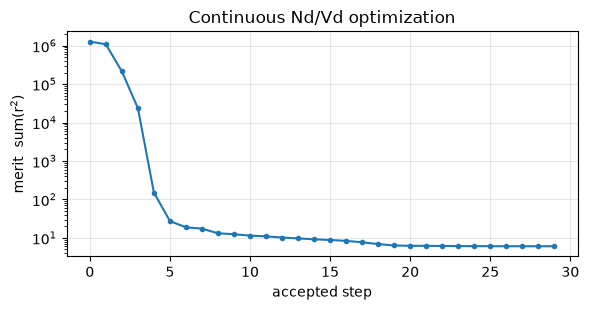

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogy(
    [r["iteration"] for r in history.records],
    [r["value"] for r in history.records],
    marker="o",
    ms=3,
)
ax.set_xlabel("accepted step")
ax.set_ylabel("merit  sum(r$^2$)")
ax.set_title("Continuous Nd/Vd optimization")
ax.grid(alpha=0.3)
fig.tight_layout()

 surface        Nd       Vd      dPgF
       1   1.67717   66.964  -0.00094
       3   1.55396   79.658  -0.00094
       4   1.40000   53.568  -0.00094
       7   1.40000   55.805  -0.00094
       8   1.96385   77.774  -0.00094
      10   1.40000   84.315  -0.00094


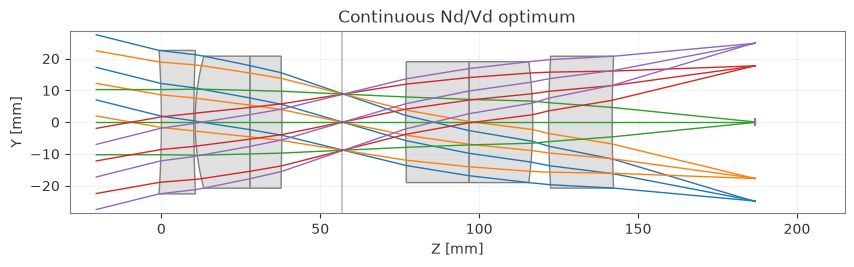

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Continuous Nd/Vd optimum'}, xlabel='Z [mm]', ylabel='Y [mm]'>)

In [8]:
print(f"{'surface':>8}{'Nd':>10}{'Vd':>9}{'dPgF':>10}")
for k in GLASS_SURFACES:
    material = lens.surfaces[k].material_post
    print(f"{k:>8}{material.nd:>10.5f}{material.vd:>9.3f}{material.dPgf:>10.5f}")

lens.draw(title="Continuous Nd/Vd optimum")

## Step 2 - snapping back to real glass

The optimum above is made of fictitious glasses. `find_closest_glass((Nd, Vd), catalog)` returns the name of the catalogue glass whose `(Nd, Vd)` is closest to the target, using the squared Euclidean distance in that plane.

Two practical points:

- The distance is **not normalised**: `Nd` spans roughly 0.3 index units while `Vd` spans roughly 70, so the metric is dominated by `Vd`. A model glass can therefore be matched to a real glass with a very different index - watch the `dist` column below.
- `find_closest_glass` takes plain names, so we keep a name -> catalogue map and instantiate every replacement with `Material(name, catalog=...)` to avoid ambiguous matches between catalogues.

The candidate list is restricted to Schott and Ohara glasses that transmit the full 0.4-0.7 um band.

In [9]:
catalogs = ("schott", "ohara")

catalog_of = {}
for catalog in catalogs:
    for name in MaterialCatalog(catalog).list():
        catalog_of.setdefault(name, catalog)

candidates = glasses_selection(0.4, 0.7, catalogs=list(catalogs))
print(f"{len(candidates)} candidate glasses from {catalogs}")

564 candidate glasses from ('schott', 'ohara')


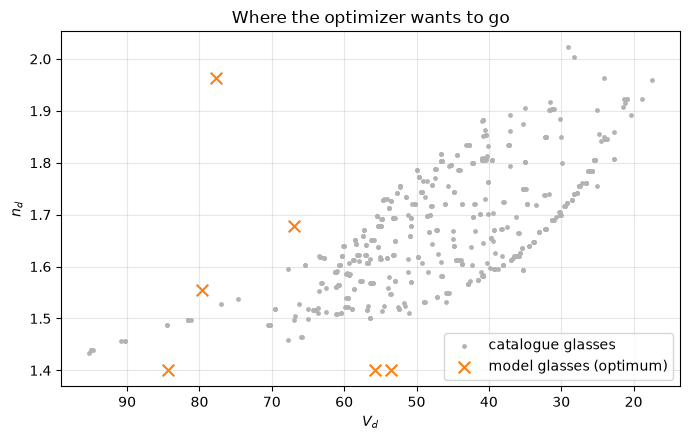

In [10]:
import warnings

from optiland.materials import OptilandMaterialWarning

# find_closest_glass and get_nd_vd resolve names without a catalogue, so
# glasses present in several catalogues warn once each. The replacement
# material itself uses the catalogue recorded in `catalog_of`.
warnings.filterwarnings("ignore", category=OptilandMaterialWarning)

glass_map = {name: get_nd_vd(name) for name in candidates}
# Glass entries without Nd/Vd in their data file come back as (0, 0); drop them.
points = np.array([pair for pair in glass_map.values() if pair[0] > 0.0])
model_points = np.array([nd_vd(lens.surfaces[k].material_post) for k in GLASS_SURFACES])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(points[:, 1], points[:, 0], s=6, c="0.7", label="catalogue glasses")
ax.scatter(
    model_points[:, 1],
    model_points[:, 0],
    marker="x",
    s=70,
    c="tab:orange",
    label="model glasses (optimum)",
)
ax.invert_xaxis()
ax.set_xlabel("$V_d$")
ax.set_ylabel("$n_d$")
ax.set_title("Where the optimizer wants to go")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()

In [11]:
print(
    f"{'surface':>8}{'model Nd':>10}{'model Vd':>10}"
    f"{'glass':>14}{'Nd':>9}{'Vd':>9}{'dist':>8}"
)

for surface_number in GLASS_SURFACES:
    material = lens.surfaces[surface_number].material_post
    nd, vd = material.nd, material.vd
    glass = find_closest_glass((nd, vd), candidates)
    replacement = Material(glass, catalog=catalog_of[glass])
    new_nd, new_vd = nd_vd(replacement)
    distance = ((nd - new_nd) ** 2 + (vd - new_vd) ** 2) ** 0.5
    lens.updater.set_material(replacement, surface_number)
    print(
        f"{surface_number:>8}{nd:>10.5f}{vd:>10.3f}"
        f"{glass:>14}{new_nd:>9.5f}{new_vd:>9.3f}{distance:>8.3f}"
    )

problem_real = make_problem(lens, optimize_glass=False)
merit_snapped = problem_real.sum_squared()
print(f"\nmerit after snapping: {merit_snapped:.1f}")

 surface  model Nd  model Vd         glass       Nd       Vd    dist


       1   1.67717    66.964        N-BK10  1.49782   66.954   0.180


       3   1.55396    79.658      S-FPL51Y  1.49700   81.138   1.482


       4   1.40000    53.568          BAL5  1.54739   53.551   0.148


       7   1.40000    55.805        N-BAK4  1.56883   55.976   0.240


       8   1.96385    77.774        N-PK51  1.52855   76.976   0.910


      10   1.40000    84.315        N-FK51  1.48656   84.468   0.176

merit after snapping: 279.3


## Re-optimizing the geometry

Substituting real glasses changes the optical power and the chromatic correction, so the merit function jumps. Only the radii and thicknesses are left as variables here; the glasses are now fixed catalogue materials.

stop reason: `ftol` termination condition is satisfied.
merit: 5.772


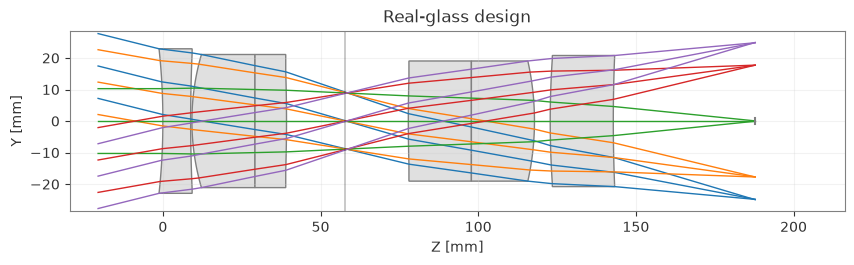

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Real-glass design'}, xlabel='Z [mm]', ylabel='Y [mm]'>)

In [12]:
result_real = minimize(problem_real, "dls")

merit_final = problem_real.sum_squared()
print(f"stop reason: {result_real.stop_reason}")
print(f"merit: {merit_final:.3f}")

lens.draw(title="Real-glass design")

## Round-trip check: real glass back to model glass

The snapped design uses catalogue glasses. Converting each glass surface back to a `ModelMaterial` with the same `Nd`, `Vd` and `dPgF` leaves the geometry untouched, so any RMS spot change measures the polynomial fit error rather than a design change. Two routes are compared on that same geometry: the visible route, selected automatically for the 0.5876 um primary, and the IR route, forced with `lambda_ref = 1.55 um` and `P_ref` evaluated at that wavelength. Both routes reproduce the d, F, C and g anchors, so both stay close to the catalogue design; the comparison quantifies the route choice rather than asserting which one must win. Deltas are percentages of the real-glass RMS, and fields are labelled by their normalized `Hy` coordinate.

In [13]:
from optiland.materials import ModelMaterial
from optiland.optimization.operand.ray import RayOperand


def rms_spots(lens):
    """RMS spot radius [um] per field, then per wavelength."""
    image_surface = lens.surfaces.num_surfaces - 1
    values = []
    for field in lens.fields.get_field_coords():
        rows = []
        for wavelength in lens.wavelengths:
            rms = RayOperand.rms_spot_size(
                lens,
                image_surface,
                field[0],
                field[1],
                16,
                wavelength.value,
                distribution="uniform",
            )
            rows.append(float(np.ravel(be.to_numpy(rms))[0]) * 1e3)
        values.append(rows)
    return values


# Keep the catalogue materials so both model routes start from the same glass.
real_materials = {k: lens.surfaces[k].material_post for k in GLASS_SURFACES}
rms_real = rms_spots(lens)

# Visible route: selected automatically for the 0.5876 um primary wavelength.
for surface_number in GLASS_SURFACES:
    nd, _ = nd_vd(lens.surfaces[surface_number].material_post)
    lens.updater.set_index(nd, surface_number)

rms_visible = rms_spots(lens)

# IR route: force lambda_ref = 1.55 um and evaluate P_ref at that wavelength.
for surface_number in GLASS_SURFACES:
    real = real_materials[surface_number]
    nd = float(np.ravel(be.to_numpy(real.n(D_LINE)))[0])
    vd = float(np.ravel(be.to_numpy(real.abbe()))[0])
    dpgf = float(np.ravel(be.to_numpy(real.dPgF()))[0])
    p_ref = float(np.ravel(be.to_numpy(real.P_ref(wavelength=1.55)))[0])
    lens.updater.set_material(
        ModelMaterial(
            nd=nd, vd=vd, dPgF=dpgf, P_ref=p_ref, lambda_ref=1.55
        ),
        surface_number,
    )

rms_ir = rms_spots(lens)

print(
    f"{'Hy (norm)':>10}{'wl [um]':>9}{'real':>9}{'visible':>9}{'IR':>9}"
    f"{'dVis [%]':>10}{'dIR [%]':>10}"
)
for i, field in enumerate(lens.fields.get_field_coords()):
    for j, wavelength in enumerate(lens.wavelengths):
        real = rms_real[i][j]
        visible = rms_visible[i][j]
        ir = rms_ir[i][j]
        d_visible = 100.0 * (visible - real) / real
        d_ir = 100.0 * (ir - real) / real
        print(
            f"{field[1]:>10.1f}{wavelength.value:>9.4f}{real:>9.4f}"
            f"{visible:>9.4f}{ir:>9.4f}{d_visible:>+10.2f}{d_ir:>+10.2f}"
        )

rms_real = np.array(rms_real)
rms_visible = np.array(rms_visible)
rms_ir = np.array(rms_ir)
mean_visible = float(np.mean(np.abs(100.0 * (rms_visible - rms_real) / rms_real)))
mean_ir = float(np.mean(np.abs(100.0 * (rms_ir - rms_real) / rms_real)))
print()
print(f"mean |delta|: visible {mean_visible:.2f} %, IR {mean_ir:.2f} %")

 Hy (norm)  wl [um]     real  visible       IR  dVis [%]   dIR [%]
      -1.0   0.4861  93.5358  93.1786  93.4869     -0.38     -0.05
      -1.0   0.5876  57.5568  57.5568  57.5568     -0.00     -0.00
      -1.0   0.6563  48.4872  48.3715  48.4715     -0.24     -0.03
      -0.7   0.4861  43.4028  43.1275  43.3653     -0.63     -0.09
      -0.7   0.5876  36.9083  36.9084  36.9083     +0.00     +0.00
      -0.7   0.6563  50.0156  50.3277  50.0583     +0.62     +0.09
       0.0   0.4861  35.6091  35.9089  35.6497     +0.84     +0.11
       0.0   0.5876  76.4849  76.4850  76.4850     +0.00     +0.00
       0.0   0.6563  95.7910  96.1890  95.8451     +0.42     +0.06
       0.7   0.4861  43.4028  43.1275  43.3653     -0.63     -0.09
       0.7   0.5876  36.9083  36.9084  36.9083     +0.00     +0.00
       0.7   0.6563  50.0156  50.3277  50.0583     +0.62     +0.09
       1.0   0.4861  93.5358  93.1786  93.4869     -0.38     -0.05
       1.0   0.5876  57.5568  57.5568  57.5568     -0.00     -

## Summary

The two-stage workflow is a fast alternative to a categorical glass search: the continuous `Nd`/`Vd` optimum is found with a handful of damped-least-squares steps, and only the final snapping step touches the catalogue.

Keep the following limitations in mind:

- **The model glasses are fictitious.** Only `Nd` and `Vd` are free here; `dPgF` was frozen at the starting value, and the family of glasses the optimizer can reach is therefore narrower than the real glass map. Making `dPgF` a variable as well would require a partial-dispersion operand.
- **`find_closest_glass` is an unweighted nearest neighbour.** Because `Vd` is numerically much larger than `Nd`, the match is essentially "same Abbe number, any index". If index accuracy matters more, restrict the candidate list, or build a custom weighted criterion (`get_neighbour_glasses` reserves `w_nd`/`w_vd` weights for this).
- **Re-optimisation is mandatory.** Snapping alone can degrade the merit function by orders of magnitude; the final local optimisation recovers most of the performance.
- **Tutorial 3e is the complementary tool.** `GlassExpert` searches the catalogue directly and can also explore glasses far from the continuous optimum, at the cost of many more merit-function evaluations.

In [14]:
print(f"{'stage':<32}{'merit':>14}")
print(f"{'starting design':<32}{merit_start:>14.3e}")
print(f"{'continuous Nd/Vd optimum':<32}{merit_continuous:>14.3f}")
print(f"{'after snapping to real glass':<32}{merit_snapped:>14.1f}")
print(f"{'after re-optimizing geometry':<32}{merit_final:>14.3f}")

stage                                    merit
starting design                      3.925e+06
continuous Nd/Vd optimum                 6.055
after snapping to real glass             279.3
after re-optimizing geometry             5.772
